<a href="https://colab.research.google.com/github/yumi-28/linear_ALgebra_homework/blob/main/%EC%84%A0%ED%98%95%EB%8C%80%EC%88%98_7%EC%A3%BC%EC%B0%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1418]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [1419]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [1420]:
def draw_rectangle(ax, p1, p2, p3, p4,color = "blue"):
  my_polygon = Polygon([p1, p2, p3, p4],color = color)
  ax.add_patch(my_polygon)

In [1421]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

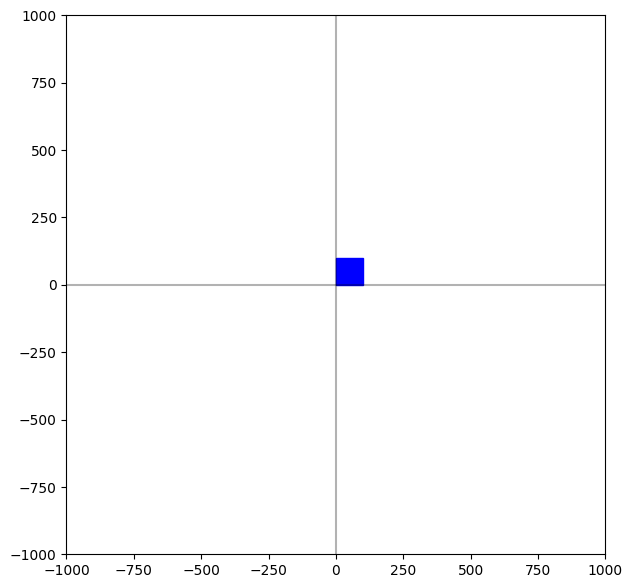

In [1422]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [1423]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [1424]:
def scale(p,sx,sy):
  hp = np.array([p[0], p[1], 1.0]) #동차좌표계로 변환

  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])  #크기 변환 행렬 생성

  q = np.dot(m, hp)  #행렬과 벡터 곱
  q = np.array([q[0], q[1]])  #2차원 좌표계로 변환
  return q

In [1425]:
def rotate(p,theta):
  hp = np.array([p[0],p[1],1.0])

  m = np.array([[np.cos(theta), -np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [1426]:
def shear_x(p, sx):
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [1427]:
def shear_y(p, sy):
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0,0.0],[0.0,0.0,1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [1428]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  s = 4
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

# 왼쪽 날개축
def draw_left_arm(ax, p1, p2, p3, p4):
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)

  #크기 변환
  q1 = scale(q1, 12, 1.5)
  q2 = scale(q2, 1, 1.5)
  q3 = scale(q3, 12,1.5)
  q4 = scale(q4, 10, 1.5)

  draw_rectangle(ax, q1, q2, q3, q4,color="blue")

  r1 = scale(q1,0.6,0.3)
  r2 = scale(q2,0.6,0.3)
  r3 = scale(q3,0.6,0.3)
  r4 = scale(q4,0.6,0.3)

  draw_rectangle(ax, r1, r2, r3, r4,color = "white")

  # 오른쪽 날개축
def draw_right_arm(ax, p1, p2, p3, p4):
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)

  #크기 변환
  q1 = scale(q1, 12, 2)
  q2 = scale(q2, 10, 2)
  q3 = scale(q3, 12, 2)
  q4 = scale(q4, 1, 2)

  draw_rectangle(ax, q1, q2, q3, q4,color="blue")

  r1 = scale(q1,0.6,0.3)
  r2 = scale(q2,0.6,0.3)
  r3 = scale(q3,0.6,0.3)
  r4 = scale(q4,0.6,0.3)

  draw_rectangle(ax, r1, r2, r3, r4,color = "white")

#왼쪽 날개
def draw_left_wing(ax,p1,p2,p3,p4):
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  q1 = scale(q1,1,12)
  q2 = scale(q2,1,12)
  q3 = scale(q3,1,12)
  q4 = scale(q4,1,12)

  q1 = translate(q1,-650,0)
  q2 = translate(q2,-650,0)
  q3 = translate(q3,-650,0)
  q4 = translate(q4,-650,0)

  q1 = shear_y(q1,0)
  q2 = shear_y(q2,-0.3)
  q3 = shear_y(q3,0.3)
  q4 = shear_y(q4,0)


  draw_rectangle(ax, q1, q2, q3, q4,color="blue")

  #오른쪽 날개
def draw_right_wing(ax,p1,p2,p3,p4):
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  q1 = scale(q1,1,12)
  q2 = scale(q2,1,12)
  q3 = scale(q3,1,12)
  q4 = scale(q4,1,12)

  q1 = translate(q1,650,0)
  q2 = translate(q2,650,0)
  q3 = translate(q3,650,0)
  q4 = translate(q4,650,0)

  q1 = shear_y(q1,0.3)
  q2 = shear_y(q2,0)
  q3 = shear_y(q3,0)
  q4 = shear_y(q4,-0.3)

  draw_rectangle(ax, q1, q2, q3, q4,color="blue")

In [1429]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  #왼쪽 날개축
  draw_left_arm(ax, p1, p2, p3, p4)

  #오른쪽 날개축
  draw_right_arm(ax, p1, p2, p3, p4)

  # 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  #왼쪽 날개
  draw_left_wing(ax, p1, p2, p3, p4)

  #오른쪽 날개
  draw_right_wing(ax, p1, p2, p3, p4)



### 3. main

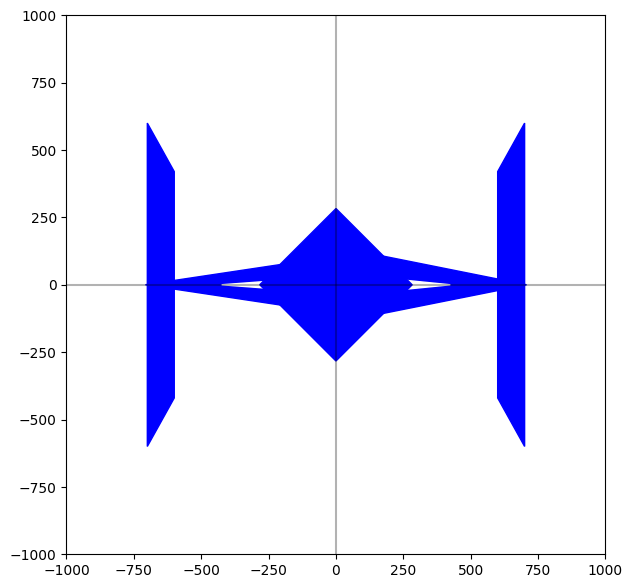

In [1430]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()